# Data-engineering job market: which skills are in demand, and which pay?
**Question.** For data roles, which tools appear most often in job ads, and which carry a salary premium **after controlling** for seniority, location and employer size?

**Data.** 2,528 Glassdoor job postings for data-engineering roles in US metros (scraped around 2020): title, salary estimate range, full description, location, company size, industry. Skills are extracted from the free-text description with word-boundary regular expressions.

**Caveats up front.** Glassdoor salaries are *estimates* (a range per posting), the sample is concentrated in Texas and California, and a regression on observational job ads shows **associations**, not the causal value of learning a skill.

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
import re, statsmodels.formula.api as smf
raw = pd.read_csv("data/glassdoor_data_engineer_jobs.csv.gz")
df = raw.replace("-1", np.nan).replace(-1, np.nan)
before = len(df)
df = df.drop_duplicates(subset=["Job Title", "Company Name", "Location", "Job Description"])
print(f"{before:,} postings, {len(df):,} after removing exact re-posts")
sal = df["Salary Estimate"].str.extract(r"\$(\d+)K-\$(\d+)K").astype(float)
df["sal_low"], df["sal_high"] = sal[0], sal[1]; df["sal_mid"] = (sal[0] + sal[1]) / 2
df["employer_est"] = df["Salary Estimate"].str.contains("Employer")
df["state"] = df["Location"].str[-2:]
t = df["Job Title"].str.lower()
df["seniority"] = np.select([t.str.contains(r"\b(?:lead|principal|staff|architect|manager|director)\b"),
                             t.str.contains(r"\b(?:senior|sr\.?|iii|iv)\b"), t.str.contains(r"\b(?:junior|jr\.?|entry|associate|i)\b$")],
                            ["lead/principal", "senior", "junior"], "mid")
df["company"] = df["Company Name"].str.split("\n").str[0]
print(df[["sal_low", "sal_high", "sal_mid"]].describe().round(1).T)
df["seniority"].value_counts()

2,528 postings, 2,388 after removing exact re-posts
           count   mean   std   min    25%    50%    75%    max
sal_low   2388.0   77.2  28.6  27.0   56.0   74.0   93.0  191.0
sal_high  2388.0  124.5  39.5  50.0  100.0  120.0  146.0  281.0
sal_mid   2388.0  100.9  32.3  38.5   80.5   97.0  116.5  217.5


seniority
mid               1779
senior             423
lead/principal     168
junior              18
Name: count, dtype: int64

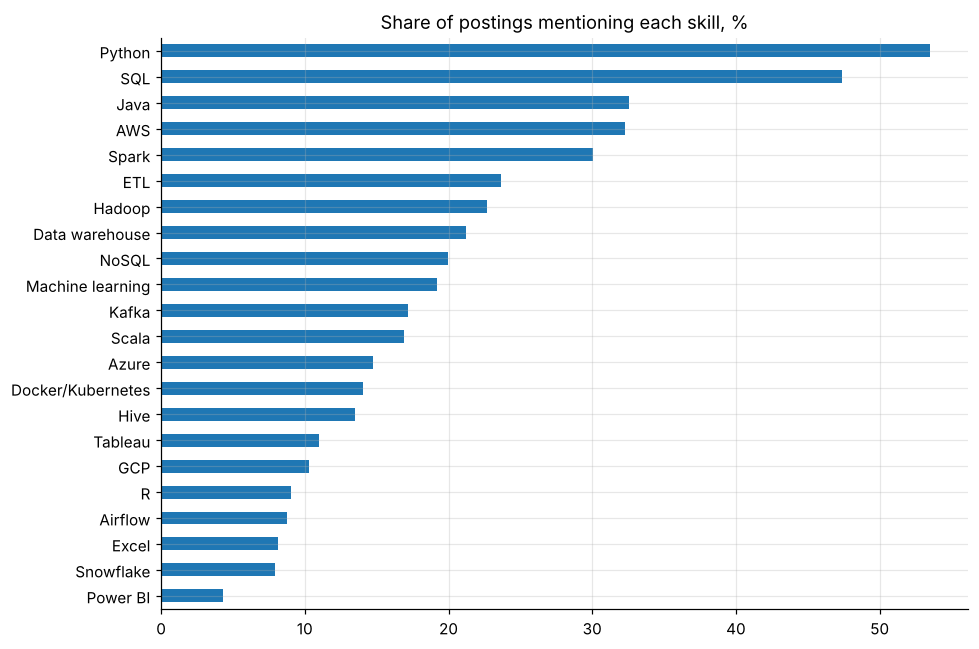

median number of listed skills per posting: 4


In [2]:
SKILLS = {"SQL": r"\bsql\b", "Python": r"\bpython\b", "Spark": r"\bspark\b", "AWS": r"\baws\b|amazon web services", "Azure": r"\bazure\b",
          "GCP": r"\bgcp\b|google cloud", "Java": r"\bjava\b", "Scala": r"\bscala\b", "Hadoop": r"\bhadoop\b", "Kafka": r"\bkafka\b",
          "Airflow": r"\bairflow\b", "Snowflake": r"\bsnowflake\b", "Hive": r"\bhive\b", "NoSQL": r"\bnosql\b|mongodb|cassandra",
          "Docker/Kubernetes": r"\bdocker\b|kubernetes|\bk8s\b", "Tableau": r"\btableau\b", "Power BI": r"power ?bi", "Excel": r"\bexcel\b",
          "Machine learning": r"machine learning|\bml\b", "ETL": r"\betl\b|\belt\b", "Data warehouse": r"data warehous", "R": r"\br\b(?![&\-/])"}
desc = df["Job Description"].str.lower()
for k, p in SKILLS.items():
    df[k] = desc.str.contains(p, regex=True)
demand = df[list(SKILLS)].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 6))
(100 * demand).plot.barh(ax=ax, color="C0", title="Share of postings mentioning each skill, %"); ax.invert_yaxis()
plt.tight_layout(); plt.savefig(IMG / "skill_demand.png", bbox_inches="tight"); plt.show()
print(f"median number of listed skills per posting: {df[list(SKILLS)].sum(axis=1).median():.0f}")

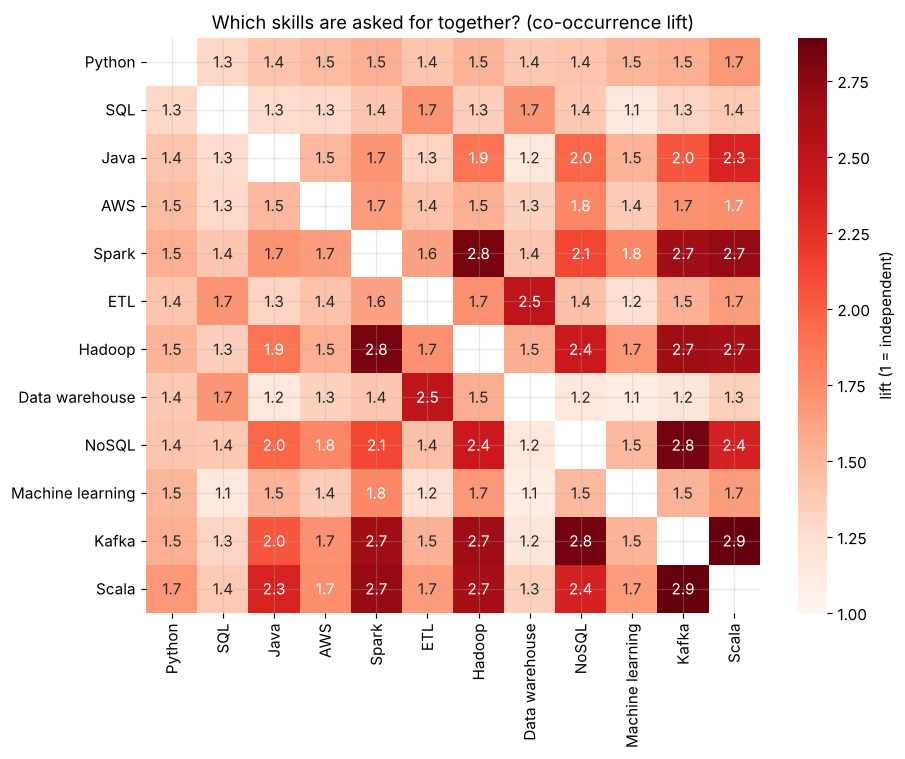

In [3]:
co = df[list(SKILLS)].astype(int)
top = demand.index[:12]
lift = pd.DataFrame({a: {b: (co[a] & co[b]).mean() / (co[a].mean() * co[b].mean()) if a != b else np.nan for b in top} for a in top})
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(lift, annot=True, fmt=".1f", cmap="Reds", vmin=1, ax=ax, cbar_kws={"label": "lift (1 = independent)"})
ax.set_title("Which skills are asked for together? (co-occurrence lift)")
plt.tight_layout(); plt.savefig(IMG / "skill_lift.png", bbox_inches="tight"); plt.show()

## Salary premia, controlling for confounders
A log-salary regression on the midpoint of the estimate:

$$\ln(\text{salary}) = \alpha + \sum_s \beta_s\,\text{skill}_s + \text{seniority} + \text{state} + \text{company size} + \varepsilon$$

$e^{\beta}-1$ is the percentage premium associated with a skill, holding the other skills and controls fixed. Standard errors are clustered by company, because many postings come from the same employer.

In [4]:
reg = df.dropna(subset=["sal_mid"]).copy()
reg["size"] = reg["Size"].fillna("unknown")
cols = [k for k in SKILLS if reg[k].mean() >= 0.03]
rename = {k: re.sub(r"\W", "_", k) for k in cols}
r2 = reg.rename(columns=rename).assign(**{rename[k]: reg[k].astype(int) for k in cols})
f = "np.log(sal_mid) ~ " + " + ".join(rename.values()) + " + C(seniority, Treatment('mid')) + C(state) + C(size)"
fit = smf.ols(f, data=r2).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(r2["company"])[0]})
prem = pd.DataFrame({"premium_%": 100 * (np.exp(fit.params[list(rename.values())]) - 1),
                     "ci_low_%": 100 * (np.exp(fit.conf_int().loc[list(rename.values()), 0]) - 1),
                     "ci_high_%": 100 * (np.exp(fit.conf_int().loc[list(rename.values()), 1]) - 1),
                     "p_value": fit.pvalues[list(rename.values())], "share_of_ads_%": 100 * reg[cols].mean().values}, index=list(rename.values()))
prem.index = cols
print(f"n = {int(fit.nobs)}, R² = {fit.rsquared:.2f}, companies = {r2['company'].nunique()}")
prem.sort_values("premium_%", ascending=False).round(3)

n = 2388, R² = 0.33, companies = 1451


,premium_%,ci_low_%,ci_high_%,p_value,share_of_ads_%
Azure,4.573,1.047,8.222,0.011,14.740
Python,4.233,1.287,7.265,0.005,53.476
Snowflake,3.384,-0.818,7.764,0.116,7.915
NoSQL,2.979,-0.160,6.217,0.063,19.975
Data warehouse,2.198,-0.966,5.464,0.175,21.231
Machine learning,1.963,-0.778,4.780,0.162,19.221
Hadoop,1.956,-1.678,5.724,0.295,22.655
Tableau,1.563,-2.295,5.573,0.433,11.013
Java,1.493,-1.158,4.215,0.272,32.580
Hive,1.302,-2.481,5.232,0.505,13.484


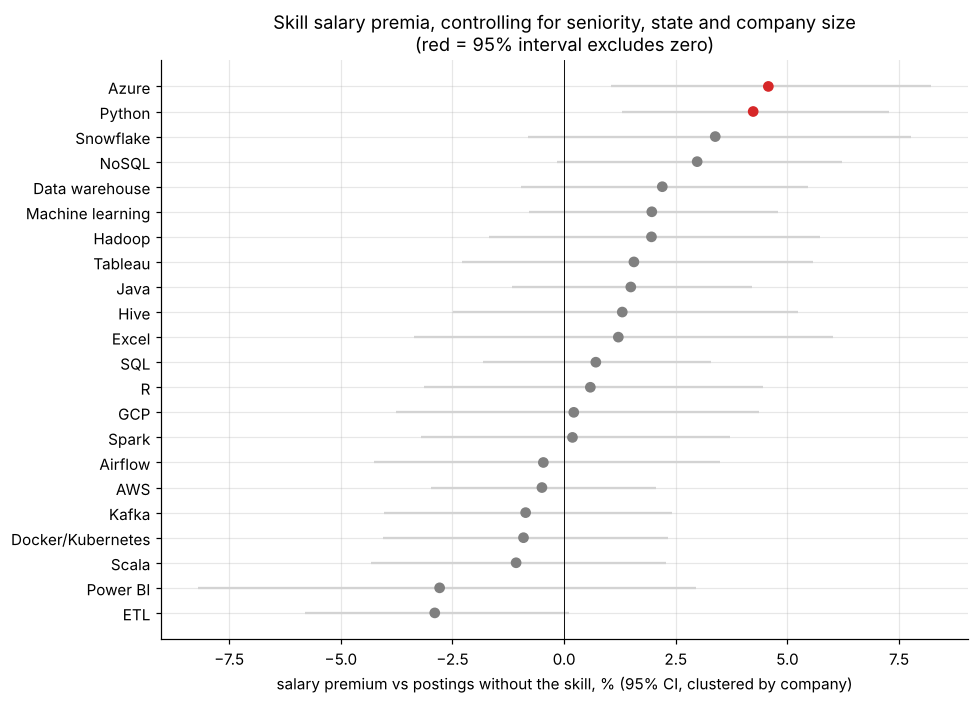

In [5]:
p = prem.sort_values("premium_%")
fig, ax = plt.subplots(figsize=(9, 6.5))
colors = ["C3" if (lo > 0 or hi < 0) else "grey" for lo, hi in zip(p["ci_low_%"], p["ci_high_%"])]
ax.errorbar(p["premium_%"], range(len(p)), xerr=[p["premium_%"] - p["ci_low_%"], p["ci_high_%"] - p["premium_%"]], fmt="none", ecolor="lightgrey")
ax.scatter(p["premium_%"], range(len(p)), c=colors, zorder=3)
ax.set_yticks(range(len(p))); ax.set_yticklabels(p.index); ax.axvline(0, c="k", lw=.6)
ax.set_xlabel("salary premium vs postings without the skill, % (95% CI, clustered by company)")
ax.set_title("Skill salary premia, controlling for seniority, state and company size\n(red = 95% interval excludes zero)")
plt.tight_layout(); plt.savefig(IMG / "skill_premia.png", bbox_inches="tight"); plt.show()

In [6]:
sen = fit.params.filter(like="seniority"); sen.index = sen.index.str.extract(r"T\.(.+)\]")[0].values
print("seniority premium vs mid-level, %:"); print((100 * (np.exp(sen) - 1)).round(1))
st = reg.groupby("state").agg(postings=("sal_mid", "size"), median_mid_k=("sal_mid", "median")).query("postings >= 50").sort_values("median_mid_k", ascending=False)
st

seniority premium vs mid-level, %:
junior           -9.0
lead/principal    2.6
senior           -1.9
dtype: float64


,postings,median_mid_k
state,,
CA,572,128.5
NY,175,104.5
AZ,184,95.5
IL,183,90.5
TX,939,87.5
PA,167,83.0
FL,128,58.0


## Findings
* **Demand:** Python (53% of 2,388 unique postings) and SQL (47%) are the baseline. Java, AWS and Spark follow at about 30% each. The median posting lists four of the tracked skills.
* **Skills come in stacks.** The big-data stack (Spark, Hadoop, Kafka, Scala, NoSQL) co-occurs at 2-3× chance, and ETL goes with data warehousing. Every pair is above 1 partly because longer job descriptions simply mention more tools.
* **Premia are small once you control for confounders.** Only Azure (+4.6%) and Python (+4.2%) have 95% intervals that exclude zero, and neither survives a Bonferroni correction for the 22 skills tested (p < 0.0023 would be needed). Most of the raw pay gap between postings is explained by location: California postings have a median midpoint of $128.5k vs $87.5k in Texas and $58k in Florida.
* **A data-quality warning hidden in the results.** Seniority barely moves the salary (senior −1.9%, lead +2.6% vs mid-level), which is implausible for real offers. Glassdoor's ranges appear to be set largely by company and location rather than by the specific role, so these premia are a lower bound on what skills are worth in actual offers.
* **For a candidate:** the safest investment is the core (Python + SQL) plus one cloud platform, then a coherent stack rather than a scattering of single tools.